## Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

## Load Dataset

In [4]:
df = pd.read_csv("iris.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
(150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


## Exploratory Data Analysis

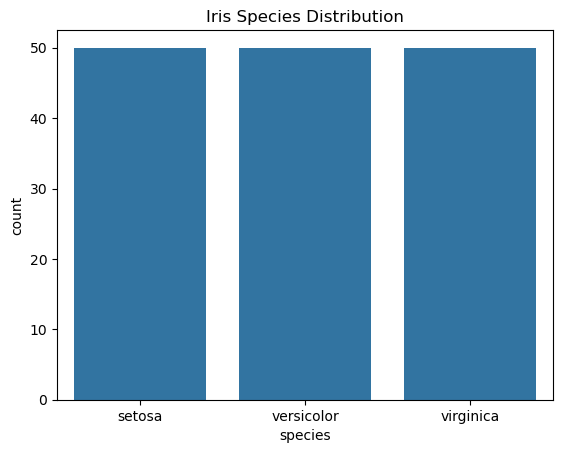

In [6]:
# Class distribution
sns.countplot(data=df, x="species")
plt.title("Iris Species Distribution")
plt.show()

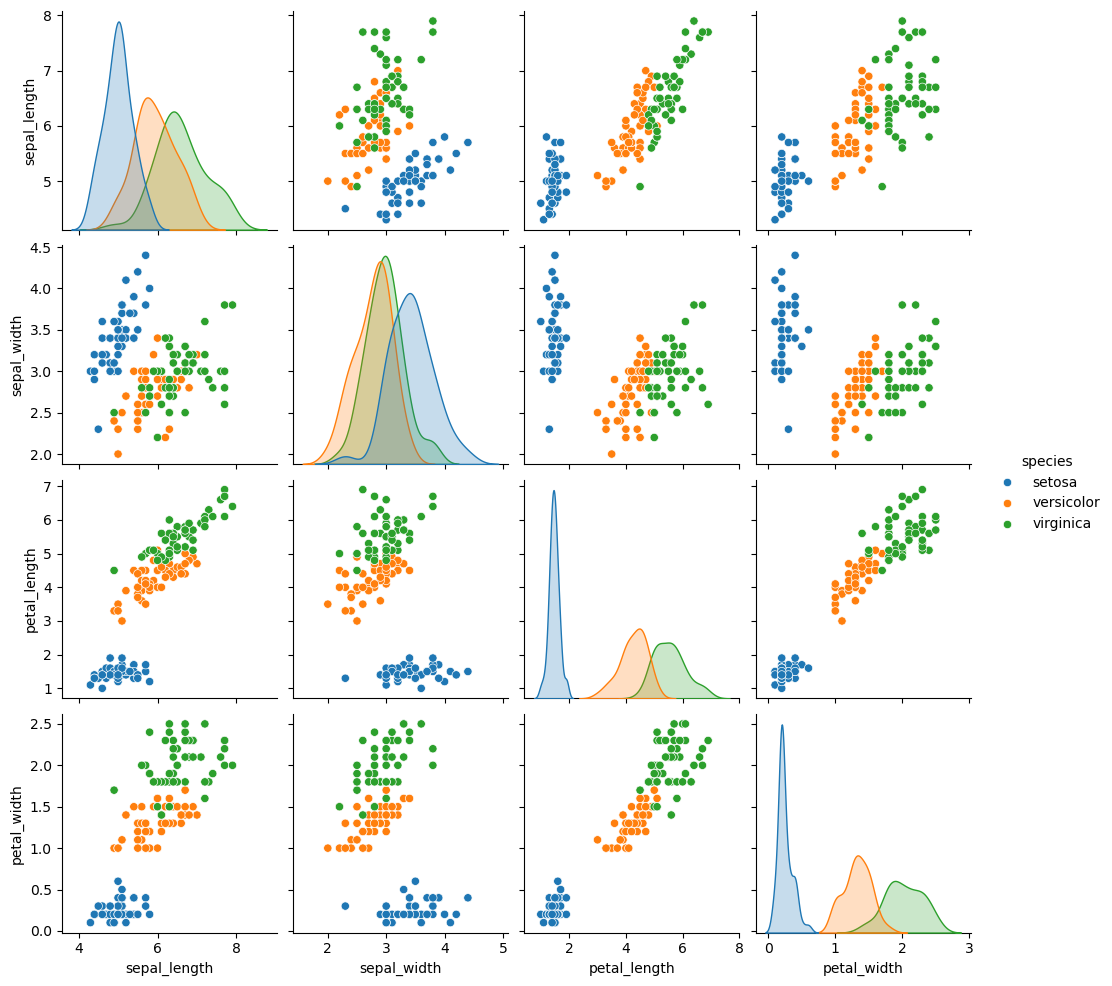

In [8]:
# Pairplot
sns.pairplot(df, hue="species")
plt.show()

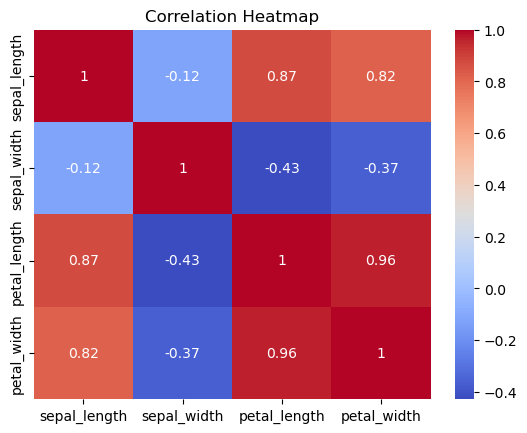

In [9]:
# Correlation heatmap
sns.heatmap(df.drop(columns="species").corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## Split Dataset (80% Training, 20% Testing)

In [10]:
X = df.drop("species", axis=1)
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (120, 4)
Testing: (30, 4)


## Feature Scaling and Model Training

In [11]:
# Create models with StandardScaler
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "Decision Tree": make_pipeline(
        StandardScaler(),
        DecisionTreeClassifier(random_state=42)
    )
}

# Train both models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully


## Evaluate Model Performance

In [12]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="weighted")
    recall = recall_score(y_test, y_pred, average="weighted")
    f1 = f1_score(y_test, y_pred, average="weighted")

    results.append([name, accuracy, precision, recall, f1])

    print("\nModel:", name)
    print(classification_report(y_test, y_pred))

# Comparison table
results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score"]
)

print(results_df)


Model: Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Model: Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.933333   0.933333  0.933333  0.933333
1        Decision Tree  0.933333   0.933333  0.933333  0.933

## Plot Confusion Matrix

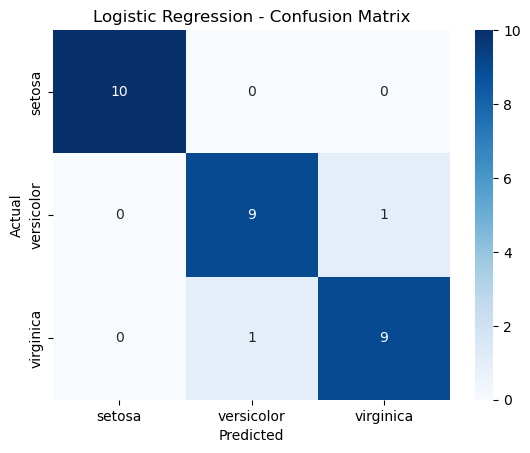

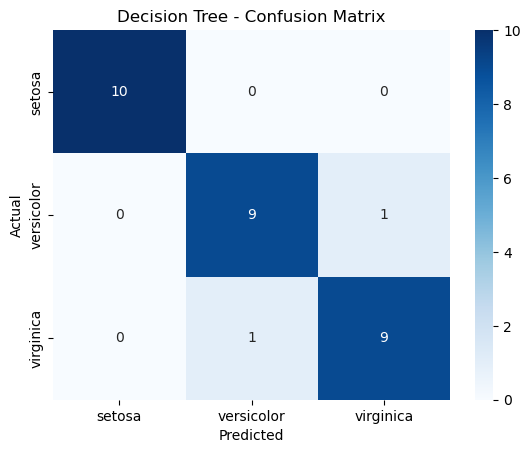

In [13]:
for name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_
    )

    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

## Compare Model Performance

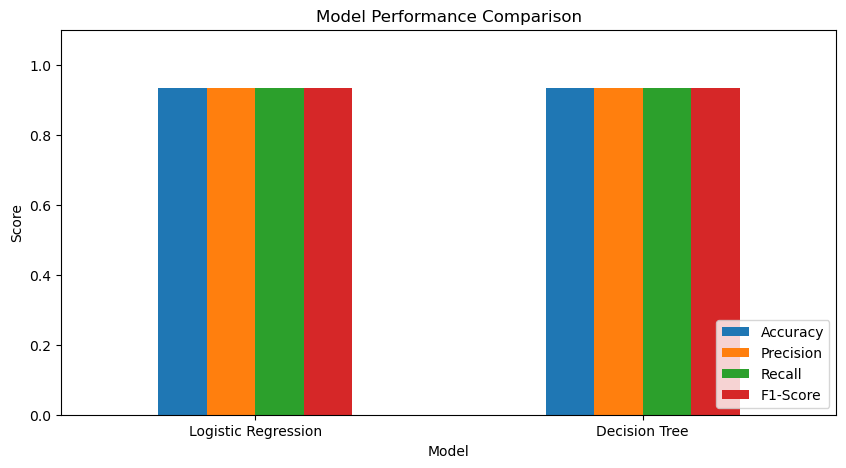

In [14]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## Decision Boundary Visualization

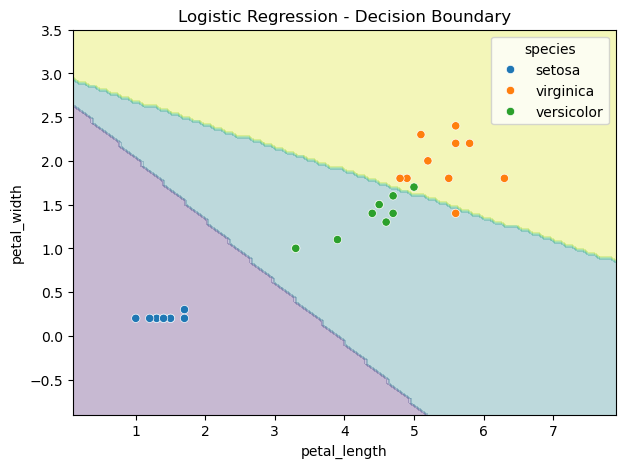

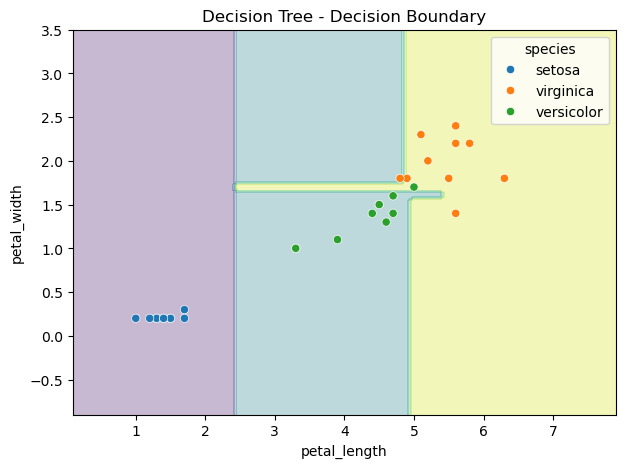

In [15]:
from sklearn.inspection import DecisionBoundaryDisplay

# Select two features for visualization
features = ["petal_length", "petal_width"]

for name, model in models.items():

    model.fit(X_train[features], y_train)

    fig, ax = plt.subplots(figsize=(7, 5))

    DecisionBoundaryDisplay.from_estimator(
        model,
        X_train[features],
        response_method="predict",
        alpha=0.3,
        ax=ax
    )

    sns.scatterplot(
        x=X_test["petal_length"],
        y=X_test["petal_width"],
        hue=y_test,
        ax=ax
    )

    plt.title(name + " - Decision Boundary")
    plt.show()

## Display Best Performing Model

In [16]:
best_model = results_df.loc[results_df["Accuracy"].idxmax()]

print("Best Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"] * 100, 2), "%")
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-Score:", round(best_model["F1-Score"], 4))

Best Model: Logistic Regression
Accuracy: 93.33 %
Precision: 0.9333
Recall: 0.9333
F1-Score: 0.9333
